# Week 1 - Exploratory Data Analysis (patient_records.csv)
Goal: profile the data, understand missing values and class balance, and see which features relate to `Reaction_Score` before modelling.

In [1]:
import sys
sys.path.insert(0, '../src')
import matplotlib.pyplot as plt
import seaborn as sns
import data_pipeline as dp

sns.set_theme(style='whitegrid')
raw = dp.load_raw('../data/patient_records.csv')
dp.profile(raw)

Shape: (500, 7)

Dtypes:
 Patient_ID                     str
Age                          int64
Biomarker_Level            float64
Pre_Existing_Conditions      int64
Vaccine_Dose_mcg           float64
Prior_Reaction_History         str
Reaction_Score               int64
dtype: object

Missing values:
 Patient_ID                  0
Age                         0
Biomarker_Level            20
Pre_Existing_Conditions     0
Vaccine_Dose_mcg            0
Prior_Reaction_History     17
Reaction_Score              0
dtype: int64

Summary statistics:
                          count unique    top  ...    50%      75%    max
Patient_ID                 500    500  P0001  ...    NaN      NaN    NaN
Age                      500.0    NaN    NaN  ...   51.0    68.25   85.0
Biomarker_Level          480.0    NaN    NaN  ...   4.82   6.9525  15.76
Pre_Existing_Conditions  500.0    NaN    NaN  ...    1.0      2.0    4.0
Vaccine_Dose_mcg         500.0    NaN    NaN  ...  84.55  118.675  150.0
Prior_Reaction

**Note on missing values.** `Prior_Reaction_History` contains the text value `"None"` (no previous reaction) for 291 patients. Pandas silently converts that text to NaN by default, so `load_raw` reads the file with `keep_default_na=False`. Only 17 cells in that column are truly empty (3.4%), and 20 in `Biomarker_Level` (4%).

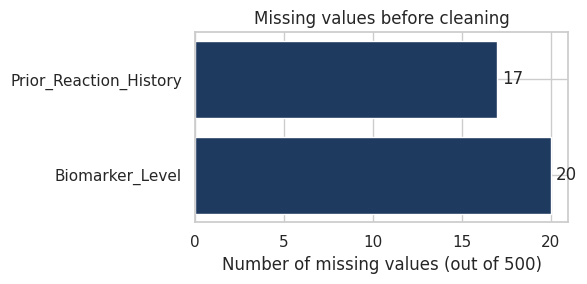

In [2]:
# Visualization 1 - missing values per column (true missing, before cleaning)
missing = raw.isnull().sum()
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(missing.index, missing.values, color='#1F3A5F')
for i, v in enumerate(missing.values):
    ax.text(v + 0.3, i, str(v), va='center')
ax.set_xlabel('Number of missing values (out of 500)')
ax.set_title('Missing values before cleaning')
fig.tight_layout()
fig.savefig('../outputs/figures/eda_missing_values.png', dpi=150)
plt.show()

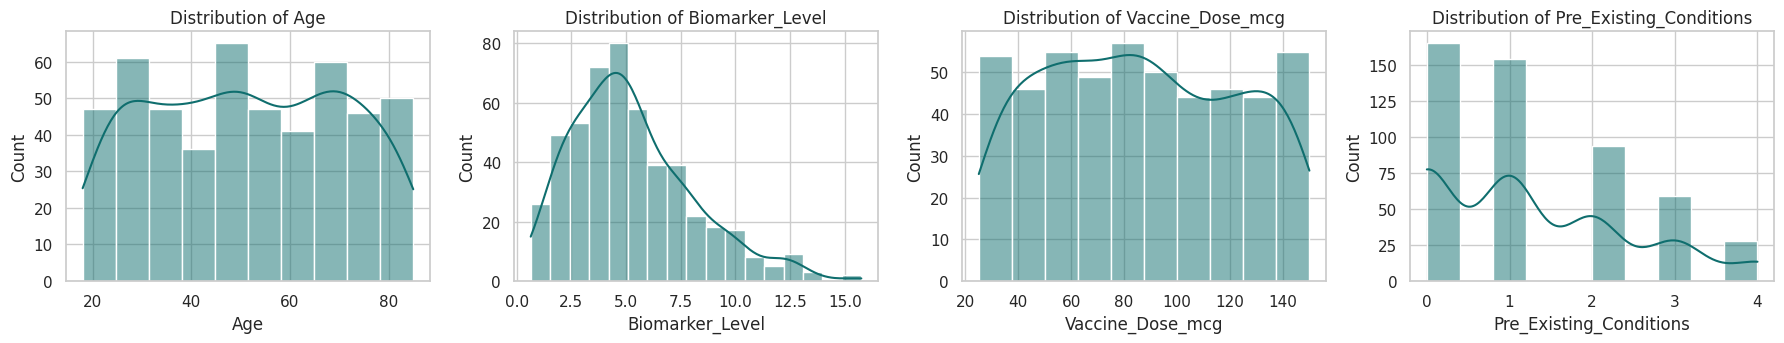

In [3]:
# Visualization 2 - distributions of the numeric features
df = dp.encode_categorical(dp.clean(raw))
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, col in zip(axes, dp.NUMERIC_COLS + ['Pre_Existing_Conditions']):
    sns.histplot(data=df, x=col, kde=True, ax=ax, color='#0F6E6E')
    ax.set_title(f'Distribution of {col}')
fig.tight_layout()
fig.savefig('../outputs/figures/eda_distributions.png', dpi=150)
plt.show()

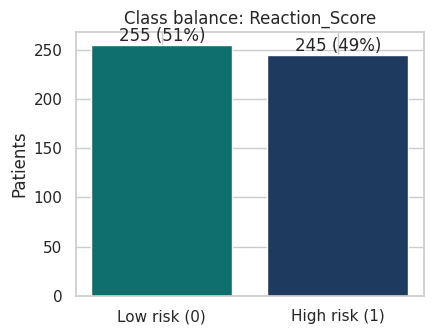

In [4]:
# Visualization 3 - class balance of the target
counts = df[dp.TARGET_COL].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(['Low risk (0)', 'High risk (1)'], counts.values, color=['#0F6E6E', '#1F3A5F'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 4, f'{v} ({v / len(df):.0%})', ha='center')
ax.set_ylabel('Patients')
ax.set_title('Class balance: Reaction_Score')
fig.tight_layout()
fig.savefig('../outputs/figures/eda_class_balance.png', dpi=150)
plt.show()

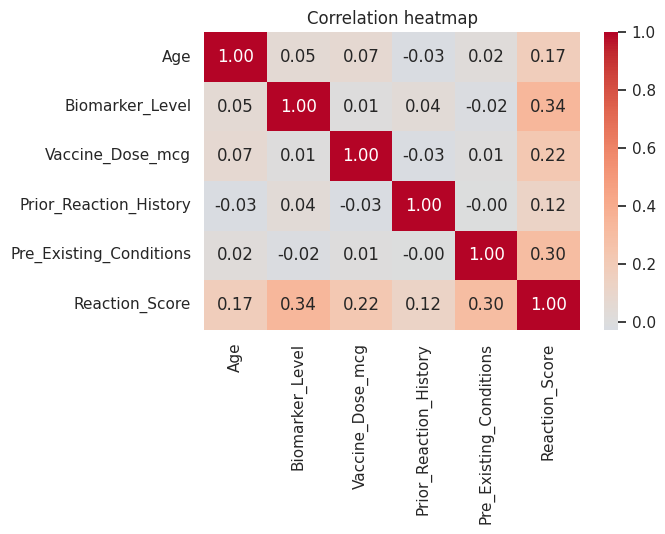

In [5]:
# Visualization 4 - correlation heatmap (Prior_Reaction_History encoded None=0, Mild=1, Moderate=2)
corr = df[dp.FEATURE_COLS + [dp.TARGET_COL]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation heatmap')
fig.tight_layout()
fig.savefig('../outputs/figures/eda_correlation_heatmap.png', dpi=150)
plt.show()

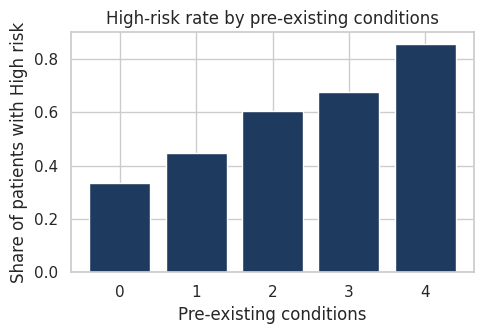

In [6]:
# Visualization 5 - high-risk rate by number of pre-existing conditions
rate = df.groupby('Pre_Existing_Conditions')[dp.TARGET_COL].mean()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(rate.index.astype(str), rate.values, color='#1F3A5F')
ax.set_xlabel('Pre-existing conditions')
ax.set_ylabel('Share of patients with High risk')
ax.set_title('High-risk rate by pre-existing conditions')
fig.tight_layout()
fig.savefig('../outputs/figures/eda_risk_by_conditions.png', dpi=150)
plt.show()

## Observations
- **Class balance:** the target is almost balanced (51% Low / 49% High), so plain accuracy and F1 are both meaningful and no resampling is needed.
- **Biomarker_Level** is right-skewed (skewness about 0.8), which is why the median, not the mean, is used for imputation. Age is roughly uniform between 18 and 85.
- **Relationships with Reaction_Score are moderate, not strong:** correlations are Biomarker_Level 0.34, Pre_Existing_Conditions 0.30, Vaccine_Dose_mcg 0.22, Age 0.17, Prior_Reaction_History 0.12. This matches the PRD's note that the data is noisy, so a realistic classifier should not be near-perfect.
- **Pre-existing conditions** show the clearest pattern: the high-risk share rises from 33% (0 conditions) to 86% (4 conditions), although only 28 patients have 4 conditions. Doses above 100 mcg have a 59% high-risk rate versus 43% for doses at or below 100 mcg.